In [383]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

dl = pd.read_csv(r"C:\Users\Haidar\PROJEK\TUGAS\ANALISIS EKSPLORASI\DATA 1\Balaji Fast Food Sales.csv")

In [384]:
dl

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,1,07-03-2022,Aalopuri,Fastfood,20,13,260,NaN,Mr.,Night
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
995,996,3/19/2023,Frankie,Fastfood,50,10,500,NaN,Mrs.,Evening
996,997,9/20/2022,Sandwich,Fastfood,60,7,420,NaN,Mr.,Evening
997,998,1/26/2023,Sandwich,Fastfood,60,13,780,NaN,Mr.,Evening
998,999,8/27/2022,Panipuri,Fastfood,20,5,100,NaN,Mrs.,Afternoon


In [385]:
df=dl.dropna()

In [386]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
5,6,11/14/2022,Vadapav,Fastfood,20,10,200,Cash,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
991,992,10/21/2022,Sandwich,Fastfood,60,5,300,Cash,Mr.,Morning
992,993,7/17/2022,Frankie,Fastfood,50,3,150,Online,Mrs.,Night
993,994,11-01-2022,Panipuri,Fastfood,20,2,40,Online,Mrs.,Evening
994,995,6/18/2022,Sugarcane juice,Beverages,25,1,25,Online,Mr.,Night


In [387]:
df['total_income']=df['quantity']*df['transaction_amount']

In [405]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,total_income,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,4500,August 2022,Tuesday
2,3,2022-11-20,Vadapav,Fastfood,20,1,20,Cash,Afternoon,20,November 2022,Sunday
3,4,2023-02-03,Sugarcane juice,Beverages,25,6,150,Online,Night,900,February 2023,Friday
4,5,2022-10-02,Sugarcane juice,Beverages,25,8,200,Online,Evening,1600,October 2022,Sunday
5,6,2022-11-14,Vadapav,Fastfood,20,10,200,Cash,Evening,2000,November 2022,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...
991,992,2022-10-21,Sandwich,Fastfood,60,5,300,Cash,Morning,1500,October 2022,Friday
992,993,2022-07-17,Frankie,Fastfood,50,3,150,Online,Night,450,July 2022,Sunday
993,994,2022-11-01,Panipuri,Fastfood,20,2,40,Online,Evening,80,November 2022,Tuesday
994,995,2022-06-18,Sugarcane juice,Beverages,25,1,25,Online,Night,25,June 2022,Saturday


In [410]:
df['total_income'].mean()

np.float64(2854.6640537514)

In [388]:
df_category = df.groupby('item_name')['item_type'].value_counts().sort_values(ascending=False)

In [389]:
df_category

item_name        item_type
Cold coffee      Beverages    138
Sugarcane juice  Beverages    136
Panipuri         Fastfood     135
Frankie          Fastfood     127
Vadapav          Fastfood     121
Aalopuri         Fastfood     119
Sandwich         Fastfood     117
Name: count, dtype: int64

In [390]:
df['item_type'].value_counts()

item_type
Fastfood     619
Beverages    274
Name: count, dtype: int64

In [391]:
df['transaction_type'].value_counts()

transaction_type
Cash      476
Online    417
Name: count, dtype: int64

In [392]:
df['time_of_sale'].value_counts()

time_of_sale
Evening      185
Night        182
Afternoon    181
Midnight     177
Morning      168
Name: count, dtype: int64

In [393]:
df['date'] = pd.to_datetime(df['date'], format='mixed').dt.strftime('%Y-%m-%d')
df['date'] = pd.to_datetime(df['date'], format='mixed')
df['month']=df['date'].dt.strftime('%B %Y')
df['day'] = df['date'].dt.day_name()

In [394]:
df=df.drop(columns='received_by') 
df.reset_index()
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,total_income,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,4500,August 2022,Tuesday
2,3,2022-11-20,Vadapav,Fastfood,20,1,20,Cash,Afternoon,20,November 2022,Sunday
3,4,2023-02-03,Sugarcane juice,Beverages,25,6,150,Online,Night,900,February 2023,Friday
4,5,2022-10-02,Sugarcane juice,Beverages,25,8,200,Online,Evening,1600,October 2022,Sunday
5,6,2022-11-14,Vadapav,Fastfood,20,10,200,Cash,Evening,2000,November 2022,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...
991,992,2022-10-21,Sandwich,Fastfood,60,5,300,Cash,Morning,1500,October 2022,Friday
992,993,2022-07-17,Frankie,Fastfood,50,3,150,Online,Night,450,July 2022,Sunday
993,994,2022-11-01,Panipuri,Fastfood,20,2,40,Online,Evening,80,November 2022,Tuesday
994,995,2022-06-18,Sugarcane juice,Beverages,25,1,25,Online,Night,25,June 2022,Saturday


In [395]:
df_sale = df.groupby('item_name').agg({'item_price':'first','quantity':'sum'}).reset_index()

In [396]:
df_sale

,item_name,item_price,quantity
0,Aalopuri,20,928
1,Cold coffee,40,1142
2,Frankie,50,1053
3,Panipuri,20,1119
4,Sandwich,60,968
5,Sugarcane juice,25,1121
6,Vadapav,20,903


In [397]:
df_order=df.groupby(['item_name','date'],as_index=False).agg({'day':'first','quantity':'sum'})

In [398]:
df_order = df_order.sort_values('date')

In [399]:
df_order

,item_name,date,day,quantity
429,Sandwich,2022-04-01,Friday,7
430,Sandwich,2022-04-02,Saturday,15
107,Cold coffee,2022-04-02,Saturday,15
431,Sandwich,2022-04-03,Sunday,1
320,Panipuri,2022-04-03,Sunday,11
...,...,...,...,...
754,Vadapav,2023-03-26,Sunday,11
532,Sandwich,2023-03-27,Monday,6
428,Panipuri,2023-03-27,Monday,34
213,Cold coffee,2023-03-29,Wednesday,27


In [400]:
df_rata=df('')

TypeError: 'DataFrame' object is not callable

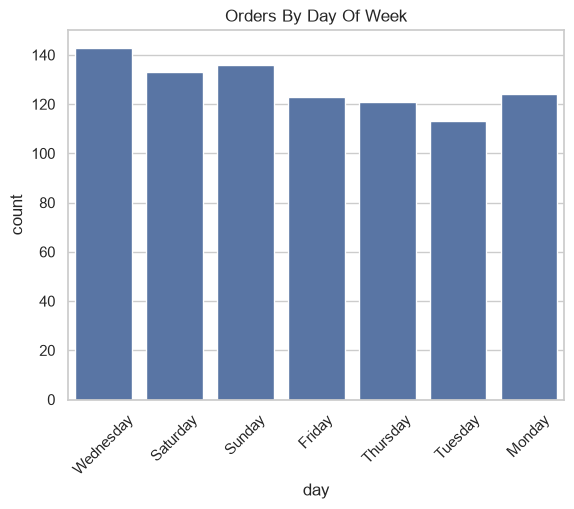

In [ ]:
oo = df_order.groupby('day').size().sort_values().index[::-1]
ax = sns.countplot(data=df, x='day', order=oo)
ax.set_title("Orders By Day Of Week")
for item in ax.get_xticklabels():
    item.set_rotation(45)



In [ ]:
df_tahun = (
    pd.to_datetime(df['month'], format='mixed').dt.to_period('M')
    .value_counts()
    .sort_index()
    .rename('sales_month')
    .to_frame()
)
df_tahun.index = df_tahun.index.to_timestamp().strftime('%B %Y')

df_tahun.reset_index()
df_tahun

,sales_month
month,
April 2022,58
May 2022,90
June 2022,61
July 2022,74
August 2022,80
September 2022,63
October 2022,89
November 2022,74
December 2022,78


In [ ]:
df_plot = df_tahun.reset_index()

In [ ]:
df_plot

,month,sales_month
0,April 2022,58
1,May 2022,90
2,June 2022,61
3,July 2022,74
4,August 2022,80
5,September 2022,63
6,October 2022,89
7,November 2022,74
8,December 2022,78
9,January 2023,80


In [ ]:
df.groupby('date').agg({'quantity': 'sum','time_of_sale':'first'})

,quantity,time_of_sale
date,,
2022-04-01,7,Evening
2022-04-02,30,Afternoon
2022-04-03,22,Morning
2022-04-04,33,Evening
2022-04-05,2,Morning
...,...,...
2023-03-25,29,Midnight
2023-03-26,12,Morning
2023-03-27,40,Afternoon


In [ ]:
df['transaction_type'].value_counts()

transaction_type
Cash      476
Online    417
Name: count, dtype: int64

In [ ]:
df.nlargest(10,'quantity')

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,August 2022,Tuesday
20,21,2022-12-21,Cold coffee,Beverages,40,15,600,Cash,Evening,December 2022,Wednesday
50,51,2022-05-16,Frankie,Fastfood,50,15,750,Online,Morning,May 2022,Monday
85,86,2023-03-09,Aalopuri,Fastfood,20,15,300,Cash,Morning,March 2023,Thursday
89,90,2022-10-29,Vadapav,Fastfood,20,15,300,Online,Night,October 2022,Saturday
91,92,2022-05-13,Aalopuri,Fastfood,20,15,300,Cash,Afternoon,May 2022,Friday
135,136,2022-08-24,Aalopuri,Fastfood,20,15,300,Online,Morning,August 2022,Wednesday
137,138,2022-09-01,Sandwich,Fastfood,60,15,900,Online,Night,September 2022,Thursday
186,187,2022-10-11,Aalopuri,Fastfood,20,15,300,Cash,Morning,October 2022,Tuesday
192,193,2023-02-05,Cold coffee,Beverages,40,15,600,Online,Midnight,February 2023,Sunday


In [ ]:
l=df.groupby('item_name')['time_of_sale'].value_counts().reset_index()
l
##nanti buat visualisasi yang nampilin perbandingan waktu di satu item kalo bisa dibuat kaya filter item

,item_name,time_of_sale,count
0,Aalopuri,Midnight,30
1,Aalopuri,Morning,25
2,Aalopuri,Afternoon,24
3,Aalopuri,Night,23
4,Aalopuri,Evening,17
5,Cold coffee,Night,33
6,Cold coffee,Morning,28
7,Cold coffee,Evening,27
8,Cold coffee,Afternoon,27
9,Cold coffee,Midnight,23


In [ ]:
plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

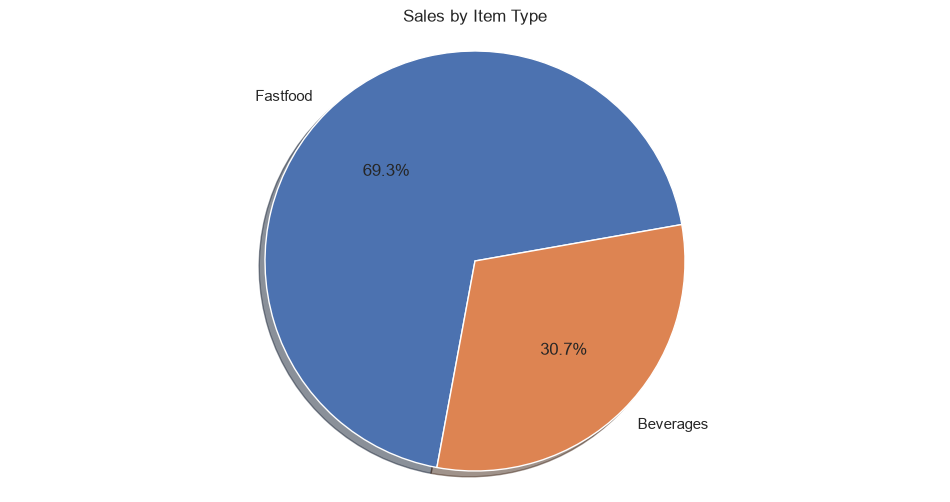

In [ ]:
plt.figure(figsize=(12,6))
df['item_type'].value_counts().plot(kind='pie',shadow=True,startangle=10, color='skyblue', autopct='%1.1f%%')
plt.title('Sales by Item Type')
plt.axis('equal')
plt.show()

In [ ]:
df_sale

,item_name,item_price,quantity
0,Aalopuri,20,928
1,Cold coffee,40,1142
2,Frankie,50,1053
3,Panipuri,20,1119
4,Sandwich,60,968
5,Sugarcane juice,25,1121
6,Vadapav,20,903


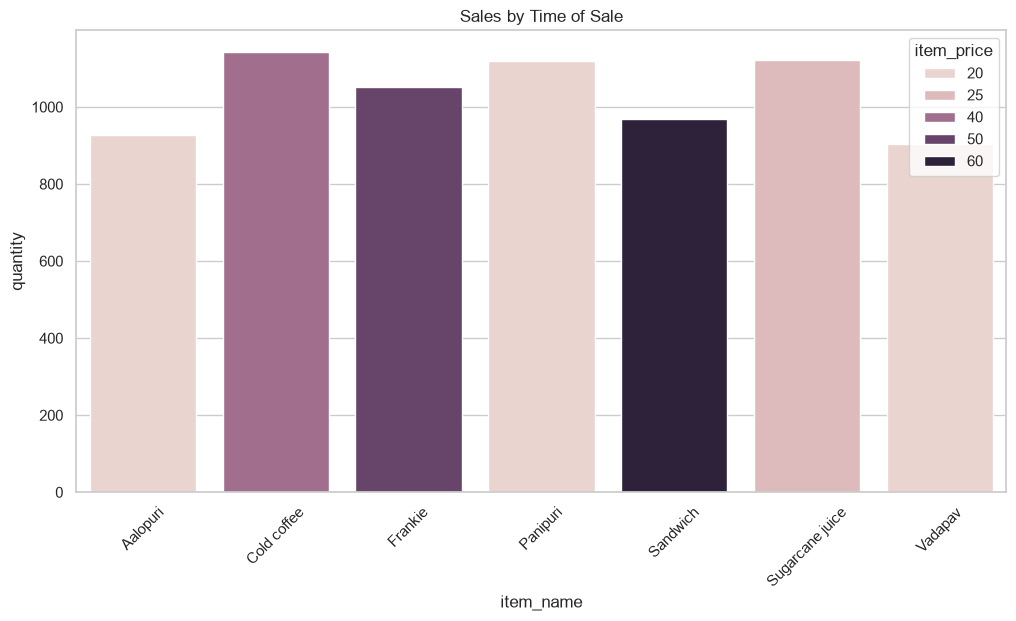

In [ ]:
plt.figure(figsize=(12,6))

sns.set_theme(style='whitegrid')
sns.barplot(data=df_sale, x = 'item_name',y='quantity',hue='item_price')
plt.xticks(rotation=45)
plt.xlabel=('Produk')
plt.ylabel=('Count')
plt.title('Sales by Time of Sale')
plt.show()

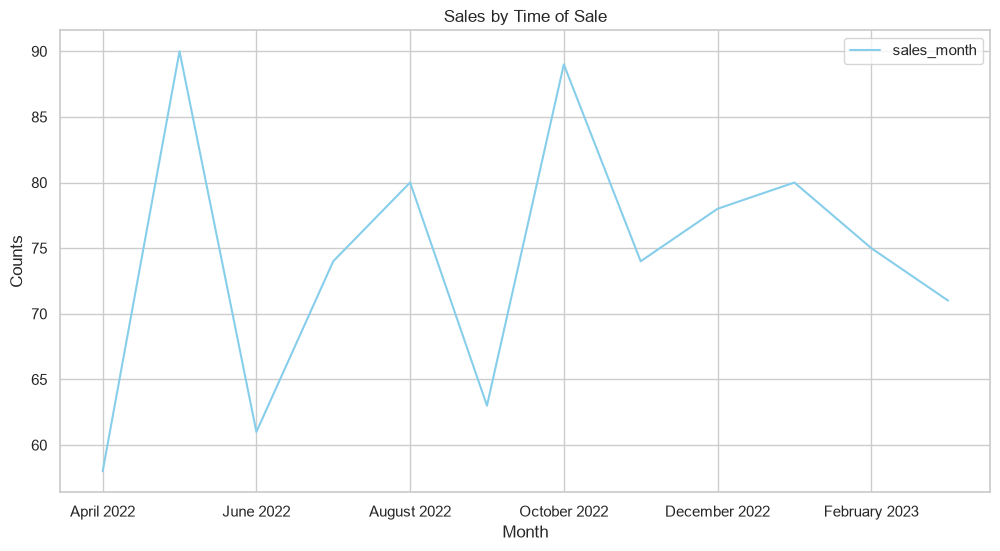

In [ ]:
ax = df_plot.plot(kind='line', x='month',figsize=(12, 6), color='skyblue',grid=True)

ax.set_xlabel('Month')
ax.set_ylabel('Counts')
ax.set_title('Sales by Time of Sale')
plt.show()

